# SK Hynix and Micron: how closely do they really move?

**FM321 Assignment 1** | Candidate number: 60773 | Data: EODHD, 2 January 2013 to 5 November 2026

## Question

SK Hynix and Micron are two of the three firms that dominate global memory-chip supply, so their share prices should respond to the same news. Yet the Korea Exchange and Nasdaq never trade at the same time. This note describes both stocks with the Chapter 1 toolkit and asks one question about their dependence:

> **Is the standard daily correlation a reliable guide to how closely SK Hynix and Micron move together?**

## Approach

1. Download daily prices for both stocks from EODHD and convert them to returns.
2. Plot prices and returns, and identify the major events in the sample.
3. Present sample statistics: moments, Jarque-Bera tests, QQ plots against the normal and Student-t, tail probabilities, autocorrelations and Ljung-Box tests.
4. Show how volatility and correlation have evolved, using rolling windows, and how correlation behaves in stress periods.
5. Test whether the non-overlapping trading hours distort the measured correlation, and what that means for risk.
6. Make a recommendation based on the results.

Only Chapter 1 methods are used.

## 1. Setup

With `USE_CACHE = True` the notebook reads the submitted data file `fm321_a1_data.csv`. With `False` it downloads the data from EODHD, which requires an `EOD_API_KEY` entry in a `.env` file. All statistics are coded from the formulas in the lecture slides using `numpy`, `pandas`, `scipy` and `matplotlib`.

In [44]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy import stats
from dotenv import load_dotenv

pd.set_option("display.width", 140)
pd.set_option("display.float_format", "{:,.4f}".format)

# Parameters
START_DATE = "2013-01-01"
DATA_FILE = "fm321_a1_data.csv"
USE_CACHE = True
FIG_DIR = "figures"
ANN = 250            # trading days per year, as in the lecture slides
ROLL_VOL = 63        # rolling volatility window, about one quarter
ROLL_CORR = 252      # rolling correlation window, about one year
LB_LAGS = 21         # Ljung-Box lags, as in the lecture slides
ACF_LAGS = 50

TICKERS = {"HY": "000660.KO", "MU": "MU.US"}
LABEL = {"HY": "SK Hynix", "MU": "Micron"}
COLOR = {"HY": "#B2182B", "MU": "#2166AC"}

# Events marked on the charts, numbered in this order
EVENTS = [
    ("2020-03-16", "Covid crash"),
    ("2023-05-25", "Nvidia AI guidance"),
    ("2024-08-05", "August 2024 sell-off"),
    ("2025-01-27", "DeepSeek"),
    ("2025-04-03", "US tariffs"),
    ("2026-07-10", "SK Hynix US listing"),
]

# Figures are sized for an A4 page with 2.54 cm margins (6.3 inches wide)
FIG_W = 6.3
os.makedirs(FIG_DIR, exist_ok=True)
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "font.size": 8,
    "axes.titlesize": 8.5, "axes.titlelocation": "left", "axes.labelsize": 8,
    "legend.fontsize": 7.5, "xtick.labelsize": 7.5, "ytick.labelsize": 7.5,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "lines.linewidth": 0.9,
})

def show(df, dec=3):
    # Display a table with thousands separators, integers without decimals and very small or large numbers in scientific form
    def f(v):
        if isinstance(v, (bool, np.bool_)) or not isinstance(v, (int, float, np.integer, np.floating)):
            return v
        v = float(v)
        if np.isnan(v):
            return ""
        if v != 0 and (abs(v) < 1e-3 or abs(v) >= 1e7):
            return f"{v:.2e}"
        if v.is_integer() and abs(v) >= 10:
            return f"{v:,.0f}"
        return f"{v:,.{dec}f}"
    display(df.map(f) if hasattr(df, "map") else df.applymap(f))

def savefig(fig, name):
    fig.savefig(os.path.join(FIG_DIR, name + ".png"), bbox_inches="tight")

def year_axis(ax, step=2):
    ax.xaxis.set_major_locator(mdates.YearLocator(step))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

def mark_events(ax, numbers=True):
    dates = [pd.Timestamp(d) for d, _ in EVENTS]
    for i, d in enumerate(dates):
        ax.axvline(d, color="grey", ls=":", lw=0.7, zorder=0)
        if numbers:
            near_prev = i > 0 and (d - dates[i - 1]).days < 150
            near_next = i < len(dates) - 1 and (dates[i + 1] - d).days < 150
            ha = "left" if near_prev else ("right" if near_next else "center")
            ax.text(d, 1.01, str(i + 1), transform=ax.get_xaxis_transform(),
                    fontsize=7, ha=ha, va="bottom", color="dimgrey")

## 2. Data

Daily prices come from EODHD: SK Hynix on the Korea Exchange (`000660.KO`, in KRW) and Micron on Nasdaq (`MU.US`, in USD). The adjusted close corrects for splits and dividends. EODHD does not adjust the open, so each open is rescaled by the same day's ratio of adjusted close to raw close, which keeps opens and closes on the same basis. Days with zero volume or missing prices are dropped.

In [45]:
def fetch(ticker, start):
    from eodhd import APIClient
    load_dotenv()
    token = os.getenv("EOD_API_KEY")
    if token is None:
        raise RuntimeError("EOD_API_KEY not found in .env")
    data = APIClient(token).get_eod_historical_stock_market_data(ticker, from_date=start)
    df = pd.DataFrame(data)
    df["date"] = pd.to_datetime(df["date"])
    df = df.set_index("date").sort_index()
    df = df[~df.index.duplicated(keep="last")]
    factor = df["adjusted_close"] / df["close"]
    return pd.DataFrame({"open": df["open"], "close": df["close"],
                         "open_adj": df["open"] * factor, "close_adj": df["adjusted_close"],
                         "volume": df["volume"]})

raw = {}
if USE_CACHE and os.path.exists(DATA_FILE):
    wide = pd.read_csv(DATA_FILE, index_col=0, parse_dates=True)
    for key in TICKERS:
        cols = [c for c in wide.columns if c.startswith(key + "_")]
        raw[key] = wide[cols].rename(columns=lambda c: c[len(key) + 1:]).dropna(how="all")
    print(f"Loaded {DATA_FILE}")
else:
    for key, ticker in TICKERS.items():
        raw[key] = fetch(ticker, START_DATE)
        time.sleep(1)
    print("Downloaded from EODHD")

# Save exactly the two series used, as the submitted data file
wide = pd.concat(raw, axis=1, sort=True)
wide.columns = [f"{k}_{c}" for k, c in wide.columns]
wide.index.name = "date"
wide.to_csv(DATA_FILE)

def clean(df):
    ok = df[["open_adj", "close_adj"]].notna().all(axis=1)
    ok &= (df["open_adj"] > 0) & (df["close_adj"] > 0) & (df["volume"] > 0)
    return df[ok].copy(), int((~ok).sum())

px, dropped = {}, {}
for key in TICKERS:
    px[key], dropped[key] = clean(raw[key])
HY, MU = px["HY"], px["MU"]
common = HY.index.intersection(MU.index)

overview = pd.DataFrame({
    LABEL[k]: {"Ticker": TICKERS[k], "First date": px[k].index[0].date(),
               "Last date": px[k].index[-1].date(), "Trading days": len(px[k]),
               "Rows dropped": dropped[k]} for k in TICKERS}).T
show(overview)
print(f"Dates traded in both markets: {len(common)}; Seoul only: {len(HY.index.difference(MU.index))}; "
      f"New York only: {len(MU.index.difference(HY.index))}")

Loaded fm321_a1_data.csv


,Ticker,First date,Last date,Trading days,Rows dropped
SK Hynix,000660.KO,2013-01-02,2026-11-05,"3,398",0.000
Micron,MU.US,2013-01-02,2026-11-04,"3,482",0.000


Dates traded in both markets: 3292; Seoul only: 106; New York only: 190


### The companies

**SK Hynix Inc.** (KRX: 000660) is a South Korean memory chipmaker within SK Group, producing DRAM and NAND flash. It is the leading supplier of high-bandwidth memory (HBM), the stacked DRAM used alongside Nvidia's AI accelerators, which has made it one of the main listed beneficiaries of AI data-centre investment.

**Micron Technology, Inc.** (Nasdaq: MU), headquartered in Boise, Idaho, is the largest US-based memory manufacturer and also produces DRAM, NAND and HBM.

With Samsung, the two firms form the three-firm oligopoly that dominates global DRAM supply, so their earnings follow the same pricing cycle. The Korea Exchange trades from 00:00 to 06:30 UTC and Nasdaq from 13:30 to 20:00 UTC (14:30 to 21:00 in US winter), so the two sessions never overlap.

## 3. Prices

Prices are rebased to 1 on the first common date and plotted on a log scale, so equal vertical distances represent equal percentage moves. Numbered lines mark the events listed in the Setup cell.

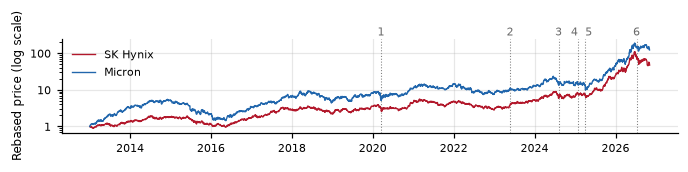

SK Hynix  end of sample 47.5x the starting price, peak 109.7x on 2026-06-22, fall from peak to end -56.7%
Micron    end of sample 123.0x the starting price, peak 187.7x on 2026-06-25, fall from peak to end -34.5%


In [46]:
fig, ax = plt.subplots(figsize=(FIG_W, 1.4))
for key, df in [("HY", HY), ("MU", MU)]:
    s = df["close_adj"] / df["close_adj"].loc[common[0]]
    ax.plot(s.index, s, color=COLOR[key], label=LABEL[key])
ax.set_yscale("log")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, p: f"{v:g}"))
ax.yaxis.set_minor_formatter(plt.NullFormatter())
ax.set_ylabel("Rebased price (log scale)")
ax.legend(loc="upper left", frameon=False)
mark_events(ax)
year_axis(ax)
fig.tight_layout()
savefig(fig, "fig1_prices")
plt.show()

for key, df in [("HY", HY), ("MU", MU)]:
    s = df["close_adj"]
    print(f"{LABEL[key]:9s} end of sample {s.iloc[-1] / s.loc[common[0]]:.1f}x the starting price, "
          f"peak {s.max() / s.loc[common[0]]:.1f}x on {s.idxmax().date()}, "
          f"fall from peak to end {s.iloc[-1] / s.max() - 1:.1%}")

**Interpretation.** Prices are clearly non-stationary, trending upwards through repeated memory cycles. Both stocks fell in the 2015 to 2016, 2018 and 2022 memory downturns and briefly in the Covid crash (1), then rose with AI demand after Nvidia's May 2023 guidance (2). The rally accelerated from mid-2025 and both stocks peaked in late June 2026, SK Hynix at 110 times and Micron at 188 times their January 2013 prices. A sharp reversal followed, shortly after SK Hynix's US listing (6): by 5 November 2026 SK Hynix was 57% and Micron 34% below their peaks.

## 4. Returns

Following the lecture notation, $P_t$ is the adjusted close and the continuously compounded return is

$$y_t = \log P_t - \log P_{t-1}.$$

For the time-zone analysis in Section 7, each return is also split at the open $O_t$ into an overnight part and a session part, which add up exactly:

$$y^{ON}_t = \log O_t - \log P_{t-1}, \qquad y^{ID}_t = \log P_t - \log O_t, \qquad y_t = y^{ON}_t + y^{ID}_t.$$

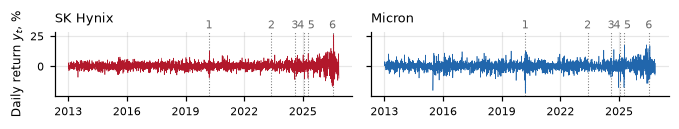

SK Hynix largest daily moves


,y_t %,overnight %,session %
date,,,
2026-07-31,26.20,24.97,1.23
2026-07-13,-16.68,-3.12,-13.56
2026-07-28,-15.84,-8.86,-6.98
2026-07-02,-15.75,-8.52,-7.23
2026-06-09,14.76,7.02,7.74
2026-06-23,-13.32,-0.72,-12.60


Micron largest daily moves


,y_t %,overnight %,session %
date,,,
2020-03-16,-22.09,-14.06,-8.02
2015-06-26,-20.03,-16.97,-3.06
2024-12-19,-17.65,-14.27,-3.38
2026-05-26,17.64,8.85,8.79
2025-04-03,-17.55,-6.63,-10.92
2025-04-09,17.24,1.00,16.24


In [47]:
def make_returns(df):
    lo, lc = np.log(df["open_adj"]), np.log(df["close_adj"])
    out = pd.DataFrame({"y": lc.diff(), "on": lo - lc.shift(1), "id": lc - lo})
    return out.dropna()

r = {key: make_returns(px[key]) for key in TICKERS}

fig, axes = plt.subplots(1, 2, figsize=(FIG_W, 1.2), sharey=True)
for ax, key in zip(axes, TICKERS):
    ax.plot(r[key].index, r[key]["y"] * 100, color=COLOR[key], lw=0.4)
    ax.set_title(f"{LABEL[key]}")
    mark_events(ax)
    year_axis(ax, 3)
axes[0].set_ylabel("Daily return $y_t$, %")
fig.tight_layout()
savefig(fig, "fig2_returns")
plt.show()

for key in TICKERS:
    top = r[key].reindex(r[key]["y"].abs().sort_values(ascending=False).index[:6]) * 100
    top.columns = ["y_t %", "overnight %", "session %"]
    print(LABEL[key], "largest daily moves")
    show(top, 2)

**Interpretation.** Unlike prices, returns fluctuate around a stable mean of close to zero, with bursts of large moves: the volatility clusters described in the lecture. Micron's largest moves are spread across the sample: Covid (1) produced its largest fall, -22.1% on 16 March 2020, earnings releases caused falls of 20.0% on 26 June 2015 and 17.7% on 19 December 2024, and the US tariffs (5) moved it -17.6% and +17.2% within a week in April 2025. SK Hynix's largest moves are all in mid-2026. Its biggest gain, +26.2% on 31 July 2026, came almost entirely at the open (+25.0%), after a strong rise in US memory stocks the previous session. That day previews the main finding of Section 7.

## 5. Sample statistics

The estimators follow the lecture slides: variance divides by $T-1$, while skewness and kurtosis are sample moments dividing by $T$. Volatility is annualised with $\sqrt{250}$. Normality is tested with

$$JB = \frac{T}{6}\,\text{Skewness}^2 + \frac{T}{24}(\text{Kurtosis}-3)^2 \sim \chi^2(2),$$

and autocorrelation with the Ljung-Box test on $N = 21$ lags,

$$LB = T(T+2)\sum_{i=1}^{N}\frac{\hat\rho_i^2}{T-i} \sim \chi^2(N).$$

In [48]:
def acf(x, nlags):
    x = np.asarray(x, dtype=float) - np.mean(x)
    denom = np.sum(x ** 2)
    return np.array([np.sum(x[i:] * x[:-i]) / denom for i in range(1, nlags + 1)])

def ljung_box(x, nlags=LB_LAGS):
    T = len(x)
    rho = acf(x, nlags)
    lb = T * (T + 2) * np.sum(rho ** 2 / (T - np.arange(1, nlags + 1)))
    return lb, stats.chi2.sf(lb, nlags)

def describe(x):
    x = pd.Series(x).dropna().values
    T = len(x)
    mu, sd = x.mean(), x.std(ddof=1)
    z = (x - mu) / sd
    skew, kurt = np.mean(z ** 3), np.mean(z ** 4)
    jb = T / 6 * skew ** 2 + T / 24 * (kurt - 3) ** 2
    lb, lb_p = ljung_box(x)
    lb2, lb2_p = ljung_box(x ** 2)
    return {"T": T, "Mean (%)": mu * 100, "Std. dev. (%)": sd * 100,
            "Ann. volatility (%)": sd * np.sqrt(ANN) * 100,
            "Min (%)": x.min() * 100, "Max (%)": x.max() * 100,
            "Skewness": skew, "Kurtosis": kurt,
            "Jarque-Bera": jb, "JB p-value": stats.chi2.sf(jb, 2),
            "LB(21) y": lb, "LB(21) y p-value": lb_p,
            "LB(21) y^2": lb2, "LB(21) y^2 p-value": lb2_p}

table1 = pd.DataFrame({LABEL[k]: describe(r[k]["y"]) for k in TICKERS})
show(table1)

on_share = {LABEL[k]: r[k]["on"].var() / r[k]["y"].var() for k in TICKERS}
print("Share of daily variance arising overnight: " +
      ", ".join(f"{k} {v:.1%}" for k, v in on_share.items()))

,SK Hynix,Micron
T,"3,397","3,481"
Mean (%),0.114,0.138
Std. dev. (%),2.767,3.144
Ann. volatility (%),43.752,49.715
Min (%),-16.685,-22.088
Max (%),26.202,17.640
Skewness,0.129,-0.126
Kurtosis,8.572,6.955
Jarque-Bera,"4,404.042","2,278.422"
JB p-value,0.000,0.000


Share of daily variance arising overnight: SK Hynix 46.1%, Micron 39.6%


### 5.1 How unlikely are the largest moves under normality?

For each stock, the probability that a normal distribution with the sample mean and standard deviation produces a daily move at least as large as the largest observed one, in either direction, together with the expected waiting time between such moves. The Student-t degrees of freedom $\nu$ implied by the sample kurtosis follow from $\text{Kurtosis} = 3 + 6/(\nu - 4)$.

In [49]:
tails = {}
for key in TICKERS:
    x = r[key]["y"]
    mu, sd = x.mean(), x.std(ddof=1)
    z = (x - mu).abs().max() / sd
    p = 2 * stats.norm.sf(z)
    kurt = table1.loc["Kurtosis", LABEL[key]]
    tails[LABEL[key]] = {"Largest move (%)": x.loc[(x - mu).abs().idxmax()] * 100,
                         "Standard deviations": z,
                         "Normal probability per day": p,
                         "Expected wait (years)": 1 / (p * ANN),
                         "Implied Student-t nu": 4 + 6 / (kurt - 3)}
show(pd.DataFrame(tails).T)

,Largest move (%),Standard deviations,Normal probability per day,Expected wait (years),Implied Student-t nu
SK Hynix,26.202,9.428,4.19e-21,9.54e+17,5.077
Micron,-22.088,7.069,1.56e-12,2.56e+09,5.517


**Interpretation.** SK Hynix's 26.2% gain on 31 July 2026 was a 9.4 standard deviation move. Under the normal distribution a move that large would occur about once in $10^{18}$ years, far longer than the age of the universe. Micron's 22.1% fall, a 7.1 standard deviation move, would occur about once every 2.6 billion years. Both stocks experienced such moves within 14 years, so the normal is a poor model for the tails. Matching the sample kurtosis gives implied Student-t degrees of freedom of about 5.1 and 5.5, close to the range of 3 to 5 the lecture reports for a typical stock.

**Interpretation.** Both stocks are far more volatile than the market index in the lecture: annualised volatility is 43.8% for SK Hynix and 49.7% for Micron. The daily mean (0.11% and 0.14%) is small next to the daily standard deviation (2.8% and 3.1%), as is typical for stock returns. Skewness is close to zero, but kurtosis of 8.6 and 7.0 is well above the normal value of 3, and the Jarque-Bera tests reject normality decisively: both stocks have fat tails.

The Ljung-Box statistics for squared returns (2,423 and 723) are many times larger than for returns (83 and 77). Volatility is strongly predictable while returns are close to unpredictable. The return tests also reject, but with more than 3,000 observations even economically negligible autocorrelations are significant. Finally, 46% of SK Hynix's daily variance and 40% of Micron's arises overnight, while each stock's own market is closed.

### 5.2 Fat tails: QQ plots

QQ plots compare the quantiles of standardised returns with those of a reference distribution: the standard normal in the top row and a Student-t with $\nu = 5$, scaled to unit variance, in the bottom row. Points that bend away from the line indicate tails fatter than the reference.

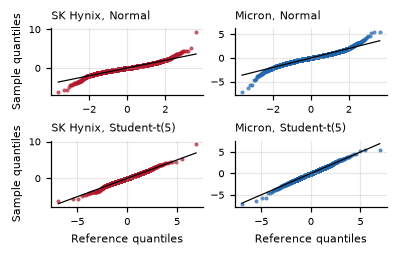

In [50]:
NU = 5
fig, axes = plt.subplots(2, 2, figsize=(3.5, 2.2))
for j, key in enumerate(TICKERS):
    x = r[key]["y"].values
    z = np.sort((x - x.mean()) / x.std(ddof=1))
    p = (np.arange(1, len(z) + 1) - 0.5) / len(z)
    refs = [(stats.norm.ppf(p), "Normal"),
            (stats.t.ppf(p, NU) * np.sqrt((NU - 2) / NU), f"Student-t({NU})")]
    for i, (q, name) in enumerate(refs):
        ax = axes[i, j]
        ax.scatter(q, z, s=3, color=COLOR[key], alpha=0.6)
        ax.plot([q.min(), q.max()], [q.min(), q.max()], color="black", lw=0.8)
        ax.set_title(f"{LABEL[key]}, {name}", fontsize=7.5)
        ax.tick_params(labelsize=6.5)
for ax in axes[:, 0]:
    ax.set_ylabel("Sample quantiles", fontsize=7)
for ax in axes[1, :]:
    ax.set_xlabel("Reference quantiles", fontsize=7)
fig.tight_layout(pad=0.3, h_pad=0.6, w_pad=0.6)
savefig(fig, "fig3_qq")
plt.show()

**Interpretation.** Against the normal, both plots show the S shape seen for the S&P-500 in the lecture: beyond about two standard deviations the sample quantiles bend away from the line in both tails, and the largest returns lie far outside it. Against the Student-t(5), consistent with the implied degrees of freedom in Section 5.1, the points lie much closer to the line, with only the most extreme observations deviating.

### 5.3 Volatility clusters

Autocorrelations of returns and squared returns, with approximate 95% bounds of $\pm 1.96/\sqrt{T}$.

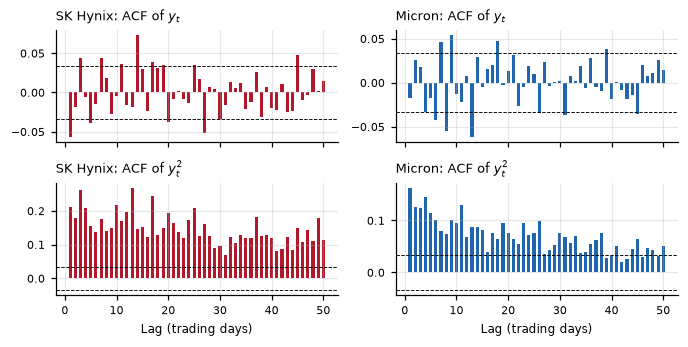

In [51]:
fig, axes = plt.subplots(2, 2, figsize=(FIG_W, 3.2), sharex=True)
lags = np.arange(1, ACF_LAGS + 1)
for j, key in enumerate(TICKERS):
    x = r[key]["y"].values
    band = 1.96 / np.sqrt(len(x))
    for i, (series, name) in enumerate([(x, "$y_t$"), (x ** 2, "$y_t^2$")]):
        ax = axes[i, j]
        ax.bar(lags, acf(series, ACF_LAGS), width=0.6, color=COLOR[key])
        for b in (band, -band):
            ax.axhline(b, color="black", ls="--", lw=0.6)
        ax.set_title(f"{LABEL[key]}: ACF of {name}")
for ax in axes[1]:
    ax.set_xlabel("Lag (trading days)")
fig.tight_layout()
savefig(fig, "fig4_acf")
plt.show()

**Interpretation.** Return autocorrelations are small, below 0.08 in absolute value, although several lie just outside the bounds. Squared-return autocorrelations are positive and well above the bounds at almost every lag: for SK Hynix they stay between about 0.1 and 0.27 over all 50 lags, while for Micron they decay from 0.16 towards 0.05. This is the volatility clustering visible in the return plot. By the weak-form efficiency argument in the lecture, returns themselves are close to unpredictable, while their volatility is highly predictable.

## 6. Volatility over time

Rolling historical volatility over 63 trading days, annualised with $\sqrt{250}$.

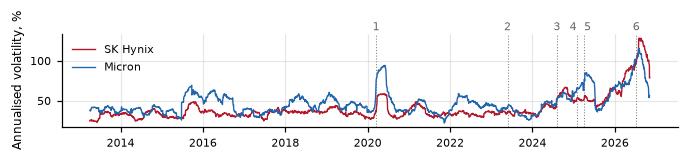

Correlation of the two rolling volatility series: 0.77
SK Hynix  rolling volatility: min 23%, max 128% on 2026-08-03
Micron    rolling volatility: min 22%, max 115% on 2026-07-31
Volatility ratio SK Hynix / Micron: mean 0.86, max 1.87 on 2026-10-29


In [52]:
vol = {k: r[k]["y"].rolling(ROLL_VOL).std() * np.sqrt(ANN) * 100 for k in TICKERS}
vol_df = pd.concat(vol, axis=1, sort=True).ffill().dropna()

fig, ax = plt.subplots(figsize=(FIG_W, 1.4))
for key in TICKERS:
    ax.plot(vol[key].index, vol[key], color=COLOR[key], label=LABEL[key])
ax.set_ylabel("Annualised volatility, %")
ax.legend(loc="upper left", frameon=False)
mark_events(ax)
year_axis(ax)
fig.tight_layout()
savefig(fig, "fig5_volatility")
plt.show()

ratio = vol_df["HY"] / vol_df["MU"]
print(f"Correlation of the two rolling volatility series: {vol_df.corr().iloc[0, 1]:.2f}")
for key in TICKERS:
    print(f"{LABEL[key]:9s} rolling volatility: min {vol[key].min():.0f}%, max {vol[key].max():.0f}% "
          f"on {vol[key].idxmax().date()}")
print(f"Volatility ratio SK Hynix / Micron: mean {ratio.mean():.2f}, max {ratio.max():.2f} on {ratio.idxmax().date()}")

**Interpretation.** Volatility moves in cycles and the two stocks share them: the correlation between their rolling volatilities is 0.77. Volatility ranged from about 22% in calm periods to more than 100%. Clusters appear in the 2015 to 2016 memory downturn, at Covid (1), when Micron's volatility exceeded 90%, after the August 2024 sell-off (3) and the US tariffs (5), and above all in mid-2026, when SK Hynix reached 128% and Micron 115%. Micron has usually been the riskier stock, with SK Hynix's volatility averaging 0.86 times Micron's, but by October 2026 the ratio had reached 1.87, as SK Hynix's volatility stayed high while Micron's fell back.

## 7. Correlation over time

### 7.1 The standard measure

The usual approach is the correlation of $y_t$ for the two stocks on the same calendar date, over dates when both markets traded. The rolling version uses a 252-day window.

In [53]:
same = pd.concat({"HY": r["HY"]["y"], "MU": r["MU"]["y"]}, axis=1, sort=True).dropna()
same_corr = same["HY"].corr(same["MU"])
same_roll = same["HY"].rolling(ROLL_CORR).corr(same["MU"])
print(f"Same-date correlation, full sample: {same_corr:.3f} (T = {len(same)})")
print(f"Rolling same-date correlation: min {same_roll.min():.2f}, max {same_roll.max():.2f}")

Same-date correlation, full sample: 0.263 (T = 3291)
Rolling same-date correlation: min 0.06, max 0.40


The same-date correlation is only 0.26. Taken at face value, two members of a three-firm oligopoly selling the same product are barely related. This is implausible, and the trading hours suggest why.

### 7.2 Aligning the two markets

The sessions never overlap. On any calendar date Seoul trades first; New York trades later, and its news can reach SK Hynix only at the next Seoul open. A same-date correlation therefore compares SK Hynix's return with a Micron return that is mostly still in the future.

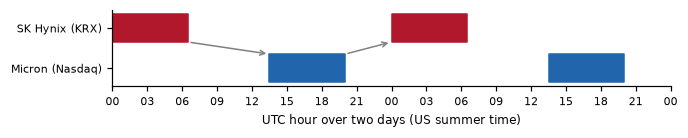

In [54]:
fig, ax = plt.subplots(figsize=(FIG_W, 1.3))
for day in [0, 24]:
    ax.broken_barh([(day, 6.5)], (1.1, 0.7), color=COLOR["HY"])
    ax.broken_barh([(day + 13.5, 6.5)], (0.1, 0.7), color=COLOR["MU"])
ax.set_yticks([0.45, 1.45])
ax.set_yticklabels(["Micron (Nasdaq)", "SK Hynix (KRX)"])
ax.set_xticks(range(0, 49, 3))
ax.set_xticklabels([f"{h % 24:02d}" for h in range(0, 49, 3)])
ax.set_xlim(0, 48)
ax.set_xlabel("UTC hour over two days (US summer time)")
ax.annotate("", xy=(13.5, 0.8), xytext=(6.5, 1.1), arrowprops=dict(arrowstyle="->", color="grey"))
ax.annotate("", xy=(24, 1.1), xytext=(20, 0.8), arrowprops=dict(arrowstyle="->", color="grey"))
ax.grid(False)
fig.tight_layout()
savefig(fig, "fig6_sessions")
plt.show()

We therefore match each session in one market with the next overnight return in the other:

* **New York to Seoul:** Micron's session $y^{ID}$ on US date $u$ with SK Hynix's overnight return $y^{ON}$ on the next Korean trading day.
* **Seoul to New York:** SK Hynix's session $y^{ID}$ on Korean date $d$ with Micron's overnight return $y^{ON}$ on the next US trading day.

When one market is closed for several days, the other market's sessions in that gap are combined into a single return from the first open to the last close. If the open prices were stale, the leader's news would appear in the follower's session instead, so the session-to-session correlation is reported as a check.

In [55]:
def match(lead_px, fol_ret, fol_index, side):
    # Assign each session of the leading market to the follower's next trading day
    pos = fol_index.searchsorted(lead_px.index, side=side)
    ok = pos < len(fol_index)
    m = lead_px.loc[ok, ["open_adj", "close_adj"]].copy()
    m["fol_date"] = fol_index[pos[ok]]
    g = m.groupby("fol_date").agg(o=("open_adj", "first"), c=("close_adj", "last"))
    g["lead"] = np.log(g["c"]) - np.log(g["o"])
    out = g[["lead"]].join(fol_ret, how="inner").dropna()
    out.index.name = "date"
    return out

ny2s = match(MU, r["HY"], HY.index, "right")   # US session u -> first Korean date after u
s2ny = match(HY, r["MU"], MU.index, "left")    # Korean session d -> first US date on or after d

def pair(x, y):
    d = pd.concat([x, y], axis=1).dropna()
    rho = d.iloc[:, 0].corr(d.iloc[:, 1])
    beta = d.cov().iloc[0, 1] / d.iloc[:, 0].var()
    return {"Correlation": rho, "95% bound": 1.96 / np.sqrt(len(d)), "beta": beta, "T": len(d)}

table2 = pd.DataFrame({
    "Same date, y_t":                        pair(same["MU"], same["HY"]),
    "Micron session -> SK Hynix overnight":  pair(ny2s["lead"], ny2s["on"]),
    "SK Hynix session -> Micron overnight":  pair(s2ny["lead"], s2ny["on"]),
    "Check: Micron session -> SK Hynix session": pair(ny2s["lead"], ny2s["id"]),
    "Check: SK Hynix session -> Micron session": pair(s2ny["lead"], s2ny["id"]),
}).T
show(table2)

,Correlation,95% bound,beta,T
"Same date, y_t",0.263,0.034,0.232,"3,291"
Micron session -> SK Hynix overnight,0.557,0.034,0.422,"3,292"
SK Hynix session -> Micron overnight,0.331,0.034,0.312,"3,291"
Check: Micron session -> SK Hynix session,0.014,0.034,0.012,"3,292"
Check: SK Hynix session -> Micron session,0.081,0.034,0.093,"3,291"


The slope $\hat\beta = \widehat{\text{Cov}}(x, y)/\hat\sigma^2_x$ from the lecture's $y = \beta x + \epsilon$ measures pass-through: the average move in the follower per 1% move in the leader.

**Interpretation.** Once the markets are aligned, the link is more than twice as strong. Micron's US session explains SK Hynix's next open with a correlation of 0.56, and a 1% move in Micron is followed by a 0.42% move in SK Hynix. News also flows the other way, from Seoul to New York (0.33), but New York leads. The check confirms that the open prices are reliable: Micron's session does not predict SK Hynix's following session (0.01), so US news is fully priced at the Seoul open.

### 7.3 How the correlation has evolved

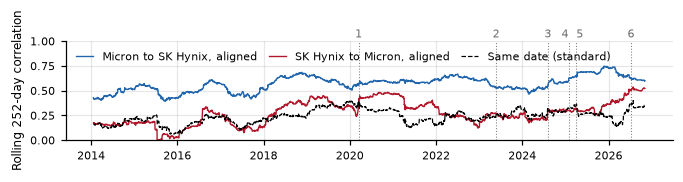

,2013 to 2019,2020 to 2022,2023 to 2026
Same-date correlation,0.219,0.233,0.312
Micron to SK Hynix correlation,0.529,0.590,0.612
Micron to SK Hynix beta,0.278,0.387,0.621
SK Hynix to Micron correlation,0.219,0.343,0.415


In [56]:
roll_ny = ny2s["lead"].rolling(ROLL_CORR).corr(ny2s["on"])
roll_s = s2ny["lead"].rolling(ROLL_CORR).corr(s2ny["on"])

fig, ax = plt.subplots(figsize=(FIG_W, 1.45))
ax.plot(roll_ny.index, roll_ny, color=COLOR["MU"], label="Micron to SK Hynix, aligned")
ax.plot(roll_s.index, roll_s, color=COLOR["HY"], label="SK Hynix to Micron, aligned")
ax.plot(same_roll.index, same_roll, color="black", ls="--", lw=0.8, label="Same date (standard)")
ax.set_ylim(0, 1)
ax.set_ylabel("Rolling 252-day correlation")
ax.legend(loc="upper left", ncol=3, frameon=False, handlelength=1.5, columnspacing=1.0)
mark_events(ax)
year_axis(ax)
fig.tight_layout()
savefig(fig, "fig7_correlation")
plt.show()

PERIODS = {"2013 to 2019": ("2013", "2019"), "2020 to 2022": ("2020", "2022"), "2023 to 2026": ("2023", "2026")}
table3 = pd.DataFrame({
    name: {"Same-date correlation": same.loc[a:b, "HY"].corr(same.loc[a:b, "MU"]),
           "Micron to SK Hynix correlation": ny2s.loc[a:b, "lead"].corr(ny2s.loc[a:b, "on"]),
           "Micron to SK Hynix beta": ny2s.loc[a:b].cov().loc["lead", "on"] / ny2s.loc[a:b, "lead"].var(),
           "SK Hynix to Micron correlation": s2ny.loc[a:b, "lead"].corr(s2ny.loc[a:b, "on"])}
    for name, (a, b) in PERIODS.items()})
show(table3)

**Interpretation.** The standard same-date correlation sits below both aligned measures throughout the sample, mostly between 0.1 and 0.4. The aligned New York to Seoul correlation has been stable between about 0.4 and 0.75, while Seoul's influence on New York has grown from below 0.2 before 2018 to about 0.5 in 2026. The link has also tightened: the pass-through from Micron to SK Hynix more than doubled, from 0.28 in 2013 to 2019 to 0.62 since 2023, while the same-date correlation rose only from 0.22 to 0.31. The standard measure misses most of this change.

### 7.4 Correlation in stress periods

The lecture shows that correlations between stocks rise sharply in crises, a form of non-linear dependence. The table compares both correlation measures over the full sample with two stress periods: the Covid crash and the 2026 memory sell-off after the June peak.

In [57]:
STRESS = {"Full sample": (None, None),
          "Covid crash, 20 Feb to 30 Apr 2020": ("2020-02-20", "2020-04-30"),
          "2026 sell-off, 22 Jun to 31 Aug 2026": ("2026-06-22", "2026-08-31")}
rows = {}
for name, (a, b) in STRESS.items():
    s_, n_ = same.loc[a:b], ny2s.loc[a:b]
    rows[name] = {"Same-date correlation": s_["HY"].corr(s_["MU"]),
                  "Aligned correlation, Micron to SK Hynix": n_["lead"].corr(n_["on"]),
                  "T": len(n_), "95% bound": 1.96 / np.sqrt(len(n_))}
table_stress = pd.DataFrame(rows).T
show(table_stress)

,Same-date correlation,"Aligned correlation, Micron to SK Hynix",T,95% bound
Full sample,0.263,0.557,"3,292",0.034
"Covid crash, 20 Feb to 30 Apr 2020",0.388,0.591,48,0.283
"2026 sell-off, 22 Jun to 31 Aug 2026",0.400,0.527,47,0.286


**Interpretation.** The standard same-date correlation rises in both stress periods, from 0.26 over the full sample to 0.39 during the Covid crash and 0.40 in the 2026 sell-off: the crisis pattern shown in the lecture. The aligned correlation barely moves (0.59 and 0.53, against 0.56). One explanation is that in stress periods large moves persist over several sessions, so more of the co-movement happens to fall on the same calendar date and the standard measure moves closer to the true link. With fewer than 50 observations per window the 95% bound is about 0.28, so neither change is statistically significant on its own and this reading is tentative. For risk management the message is the same as before: the aligned measure is the more stable guide.

## 8. What this means for portfolio risk

If the low daily correlation is a timing effect, it should disappear when returns are measured over longer horizons, because a half-day misalignment matters less over a week or a month. The table uses non-overlapping $h$-day returns on dates when both markets traded. For a 50/50 portfolio, simple returns are combined as $R_{t,\pi} = w'R_t$ and volatility is annualised with $\sqrt{250/h}$.

,T,Correlation,95% bound,SK Hynix vol (%),Micron vol (%),50/50 portfolio vol (%)
h (days),,,,,,
1,"3,291",0.294,0.034,44.483,51.009,38.433
2,"1,645",0.503,0.048,42.512,50.105,40.228
5,658,0.658,0.076,42.554,52.413,43.417
10,329,0.712,0.108,42.273,49.855,42.707
21,156,0.767,0.157,45.465,51.225,45.634


50/50 volatility: daily data 38.4%, monthly data 45.6%, difference 7.2 percentage points
Position scale that keeps risk at the level daily data report: 0.84


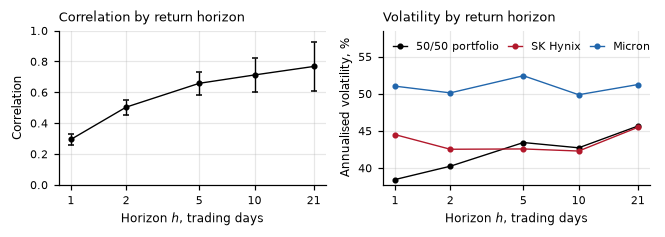

In [58]:
HORIZONS = [1, 2, 5, 10, 21]
P = pd.concat({"HY": HY["close_adj"], "MU": MU["close_adj"]}, axis=1, sort=True).loc[common]
rows = []
for h in HORIZONS:
    yh = np.log(P).iloc[::h].diff().dropna()
    Rh = P.iloc[::h].pct_change().dropna()
    Rp = 0.5 * Rh["HY"] + 0.5 * Rh["MU"]
    s = np.sqrt(ANN / h) * 100
    rows.append({"h (days)": h, "T": len(yh), "Correlation": yh["HY"].corr(yh["MU"]),
                 "95% bound": 1.96 / np.sqrt(len(yh)),
                 "SK Hynix vol (%)": Rh["HY"].std() * s, "Micron vol (%)": Rh["MU"].std() * s,
                 "50/50 portfolio vol (%)": Rp.std() * s})
table4 = pd.DataFrame(rows).set_index("h (days)")
show(table4)

vol_daily, vol_month = table4.loc[1, "50/50 portfolio vol (%)"], table4.loc[21, "50/50 portfolio vol (%)"]
print(f"50/50 volatility: daily data {vol_daily:.1f}%, monthly data {vol_month:.1f}%, "
      f"difference {vol_month - vol_daily:.1f} percentage points")
print(f"Position scale that keeps risk at the level daily data report: {vol_daily / vol_month:.2f}")

fig, axes = plt.subplots(1, 2, figsize=(FIG_W, 2.2))
axes[0].errorbar(table4.index, table4["Correlation"], yerr=table4["95% bound"],
                 marker="o", ms=3, color="black", capsize=2)
axes[0].set_ylim(0, 1)
axes[0].set_ylabel("Correlation")
axes[0].set_title("Correlation by return horizon")
axes[1].plot(table4.index, table4["50/50 portfolio vol (%)"], marker="o", ms=3, color="black", label="50/50 portfolio")
axes[1].plot(table4.index, table4["SK Hynix vol (%)"], marker="o", ms=3, color=COLOR["HY"], label="SK Hynix")
axes[1].plot(table4.index, table4["Micron vol (%)"], marker="o", ms=3, color=COLOR["MU"], label="Micron")
axes[1].set_ylabel("Annualised volatility, %")
axes[1].set_title("Volatility by return horizon")
lo, hi = axes[1].get_ylim()
axes[1].set_ylim(lo, hi + 0.35 * (hi - lo))
axes[1].legend(loc="upper left", ncol=3, frameon=False, handlelength=1.2, columnspacing=0.8)
for ax in axes:
    ax.set_xscale("log")
    ax.set_xticks(HORIZONS)
    ax.set_xticklabels(HORIZONS)
    ax.minorticks_off()
    ax.set_xlabel("Horizon $h$, trading days")
fig.tight_layout()
savefig(fig, "fig8_horizon")
plt.show()

**Interpretation.** Correlation rises from 0.29 at one day to 0.66 at a week and 0.77 at a month. The single-stock volatilities barely change with the horizon, so the rise in portfolio volatility comes entirely from correlation. A 50/50 portfolio shows 38.4% annualised volatility on daily data but 45.6% on monthly data. A risk report built on daily same-date data would understate this portfolio's volatility by about 7 percentage points and overstate the benefit of diversification.

## 9. Overnight hedge

Nearly half of SK Hynix's variance arrives overnight, and Section 7 shows that much of it is driven by Micron's US session. A desk holding SK Hynix can therefore hedge overnight by selling $h_t$ units of Micron per unit of SK Hynix at the US open and buying them back at the US close. The hedge ratio is the pass-through $\hat\beta$, estimated each day on the previous 252 observations only, so the test uses no future information:

$$h_t = \frac{\widehat{\text{Cov}}(R^{ON}_{HY}, R^{ID}_{MU})}{\hat\sigma^2(R^{ID}_{MU})}.$$

Returns are simple returns $R_t$ in local currency. Micron is very liquid, so a trading cost of 1 basis point per side is assumed.

,Ann. volatility (%),1% quantile (%),Worst day (%)
Unhedged,45.27,-7.62,-15.37
Hedged,41.13,-6.42,-16.35


Backtest 2014-01-22 to 2026-11-05
Variance reduction: overnight 35.2%, daily 17.5%
Since 2023: overnight 37.2%, daily 21.1%
Hedge ratio: mean 0.38, 2026 average 0.66
Annual fee cost 1.92%, total annual effect on return -4.80%


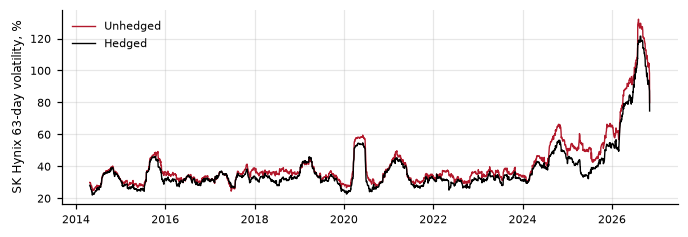

In [59]:
COST = 1 / 1e4
H = pd.DataFrame({"R_mu": np.expm1(ny2s["lead"]), "R_on": np.expm1(ny2s["on"]), "R_y": np.expm1(ny2s["y"])})
H["h"] = (H["R_mu"].rolling(ROLL_CORR).cov(H["R_on"]) / H["R_mu"].rolling(ROLL_CORR).var()).shift(1)
H = H.dropna()
H["hedge"] = -H["h"] * H["R_mu"] - 2 * COST * H["h"].abs()
H["R_on_hedged"] = H["R_on"] + H["hedge"]
H["R_y_hedged"] = H["R_y"] + H["hedge"]

def risk(x):
    return {"Ann. volatility (%)": x.std() * np.sqrt(ANN) * 100,
            "1% quantile (%)": x.quantile(0.01) * 100, "Worst day (%)": x.min() * 100}

table5 = pd.DataFrame({"Unhedged": risk(H["R_y"]), "Hedged": risk(H["R_y_hedged"])}).T
show(table5, 2)

def var_cut(d, col_h, col_u):
    return (1 - d[col_h].var() / d[col_u].var()) * 100

print(f"Backtest {H.index[0].date()} to {H.index[-1].date()}")
print(f"Variance reduction: overnight {var_cut(H, 'R_on_hedged', 'R_on'):.1f}%, daily {var_cut(H, 'R_y_hedged', 'R_y'):.1f}%")
print(f"Since 2023: overnight {var_cut(H.loc['2023':], 'R_on_hedged', 'R_on'):.1f}%, "
      f"daily {var_cut(H.loc['2023':], 'R_y_hedged', 'R_y'):.1f}%")
print(f"Hedge ratio: mean {H['h'].mean():.2f}, 2026 average {H.loc['2026', 'h'].mean():.2f}")
print(f"Annual fee cost {(2 * COST * H['h'].abs()).mean() * ANN * 100:.2f}%, "
      f"total annual effect on return {H['hedge'].mean() * ANN * 100:.2f}%")

fig, ax = plt.subplots(figsize=(FIG_W, 2.2))
for col, lab, colr in [("R_y", "Unhedged", COLOR["HY"]), ("R_y_hedged", "Hedged", "black")]:
    ax.plot(H.index, H[col].rolling(ROLL_VOL).std() * np.sqrt(ANN) * 100, color=colr, label=lab)
ax.set_ylabel("SK Hynix 63-day volatility, %")
ax.legend(loc="upper left", frameon=False)
year_axis(ax)
fig.tight_layout()
savefig(fig, "fig9_hedge")
plt.show()

**Interpretation.** The hedge ratio, estimated on past data only, averaged 0.38 and reached 0.66 in 2026 as the link tightened. The hedge cut overnight variance by 35% and daily variance by 17.5%, lowering SK Hynix's annualised volatility from 45.3% to 41.1% and its 1% daily quantile from -7.6% to -6.4%. It cannot offset shocks that start in Seoul's own session, so the worst day is not improved. Fees are about 1.9% a year, but being short Micron during its 2025 and 2026 rally took the total cost to 4.8% a year. The hedge is insurance against overnight gaps, not a source of return.

## 10. Recommendation

**Measure the risk of SK Hynix and Micron, and of any pair that trades in different time zones, on aligned or weekly returns, not same-date daily returns.** The same-date correlation of 0.26 understates the link, which is 0.56 once the markets are aligned and 0.77 at a monthly horizon. A 50/50 book carries 45.6% volatility, not the 38.4% that daily data report. To hold the risk the desk believes it is running, it should scale such a position to about 84% of its current size.

**For a desk that holds SK Hynix, hedge overnight exposure by selling Micron during US hours.** At a hedge ratio re-estimated daily on the past year, 0.66 on average in 2026, the hedge removes about a third of overnight variance for fees of about 2% a year. It suits a desk that needs to limit overnight gap risk, not one seeking return, because it gives up Micron's gains in a rally and does not protect against shocks that start in Seoul.